Leyendo: ./CCNN2018_IMACEC_01_A (No minero).xlsx 
Observaciones procesadas: 164 


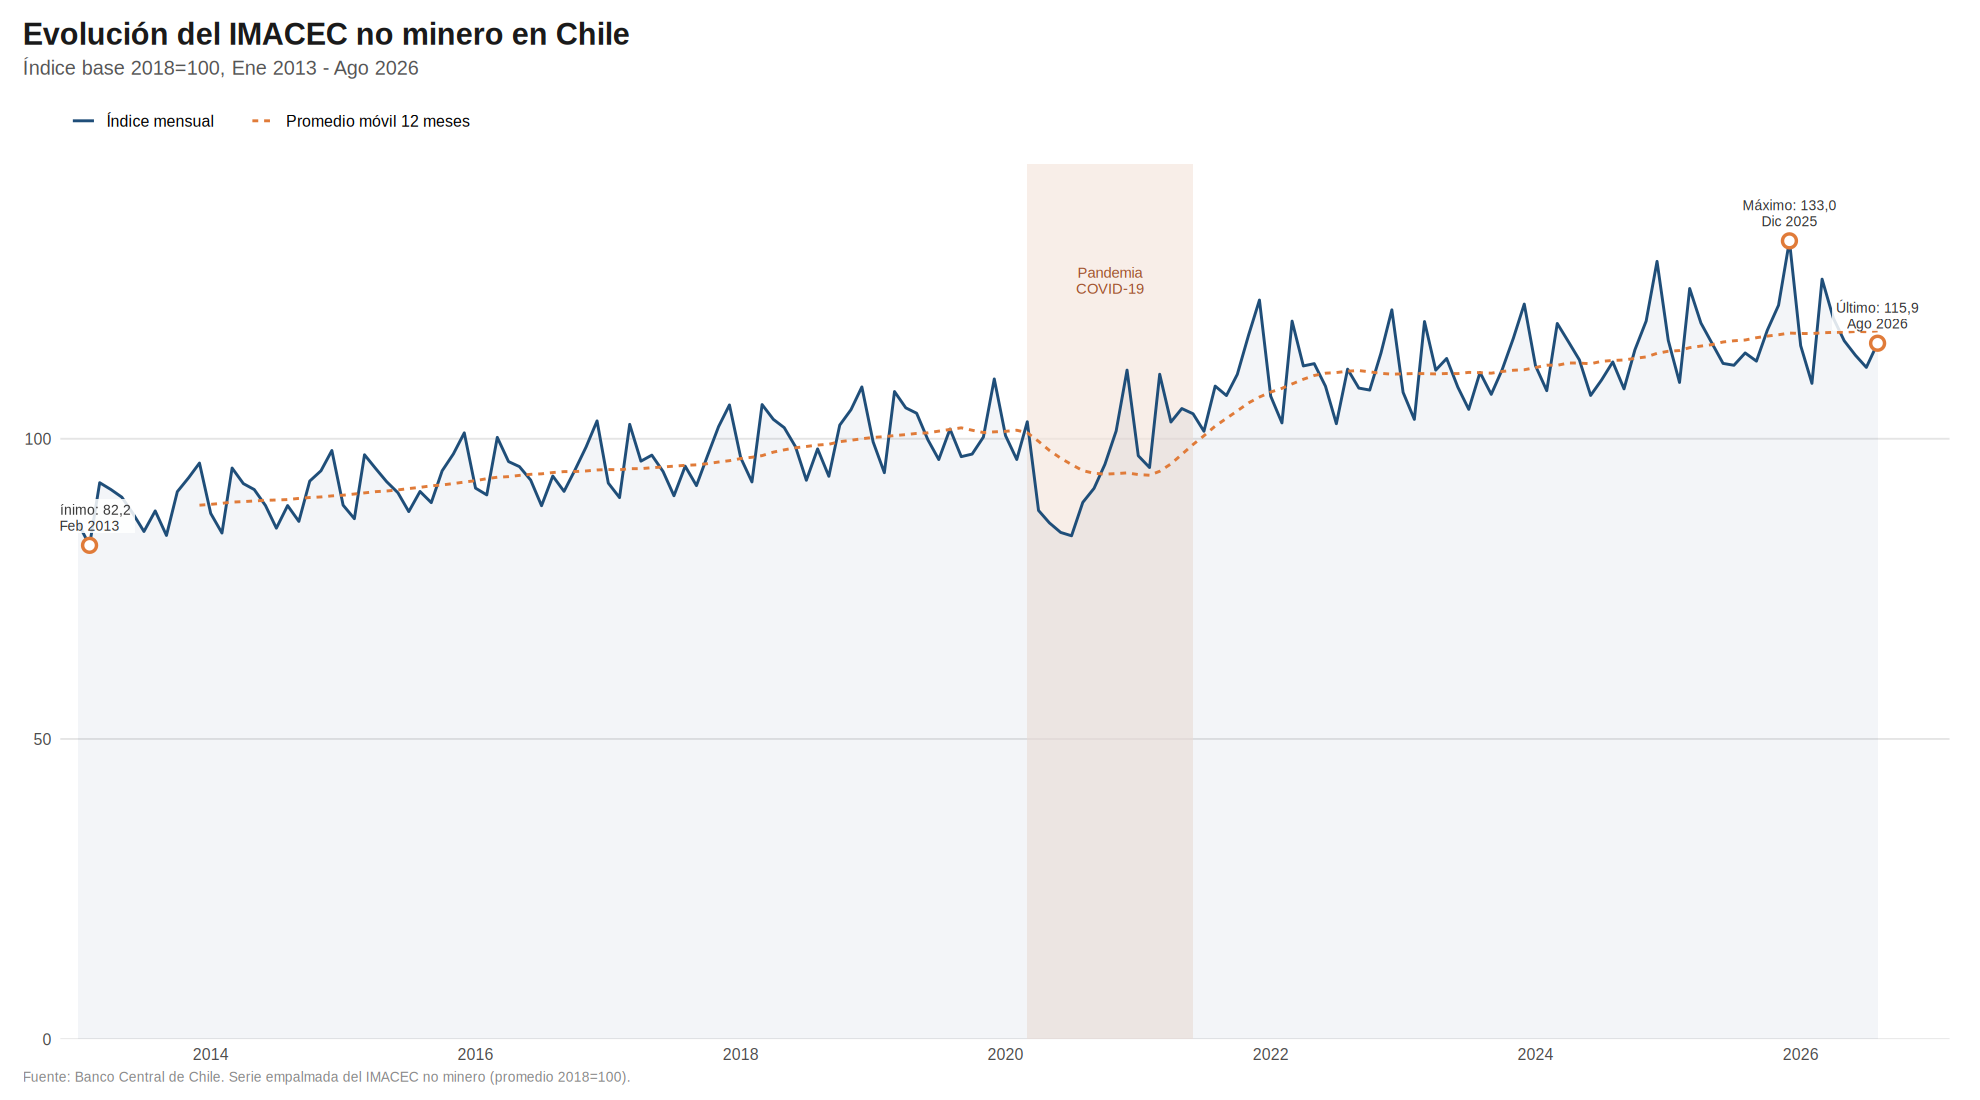

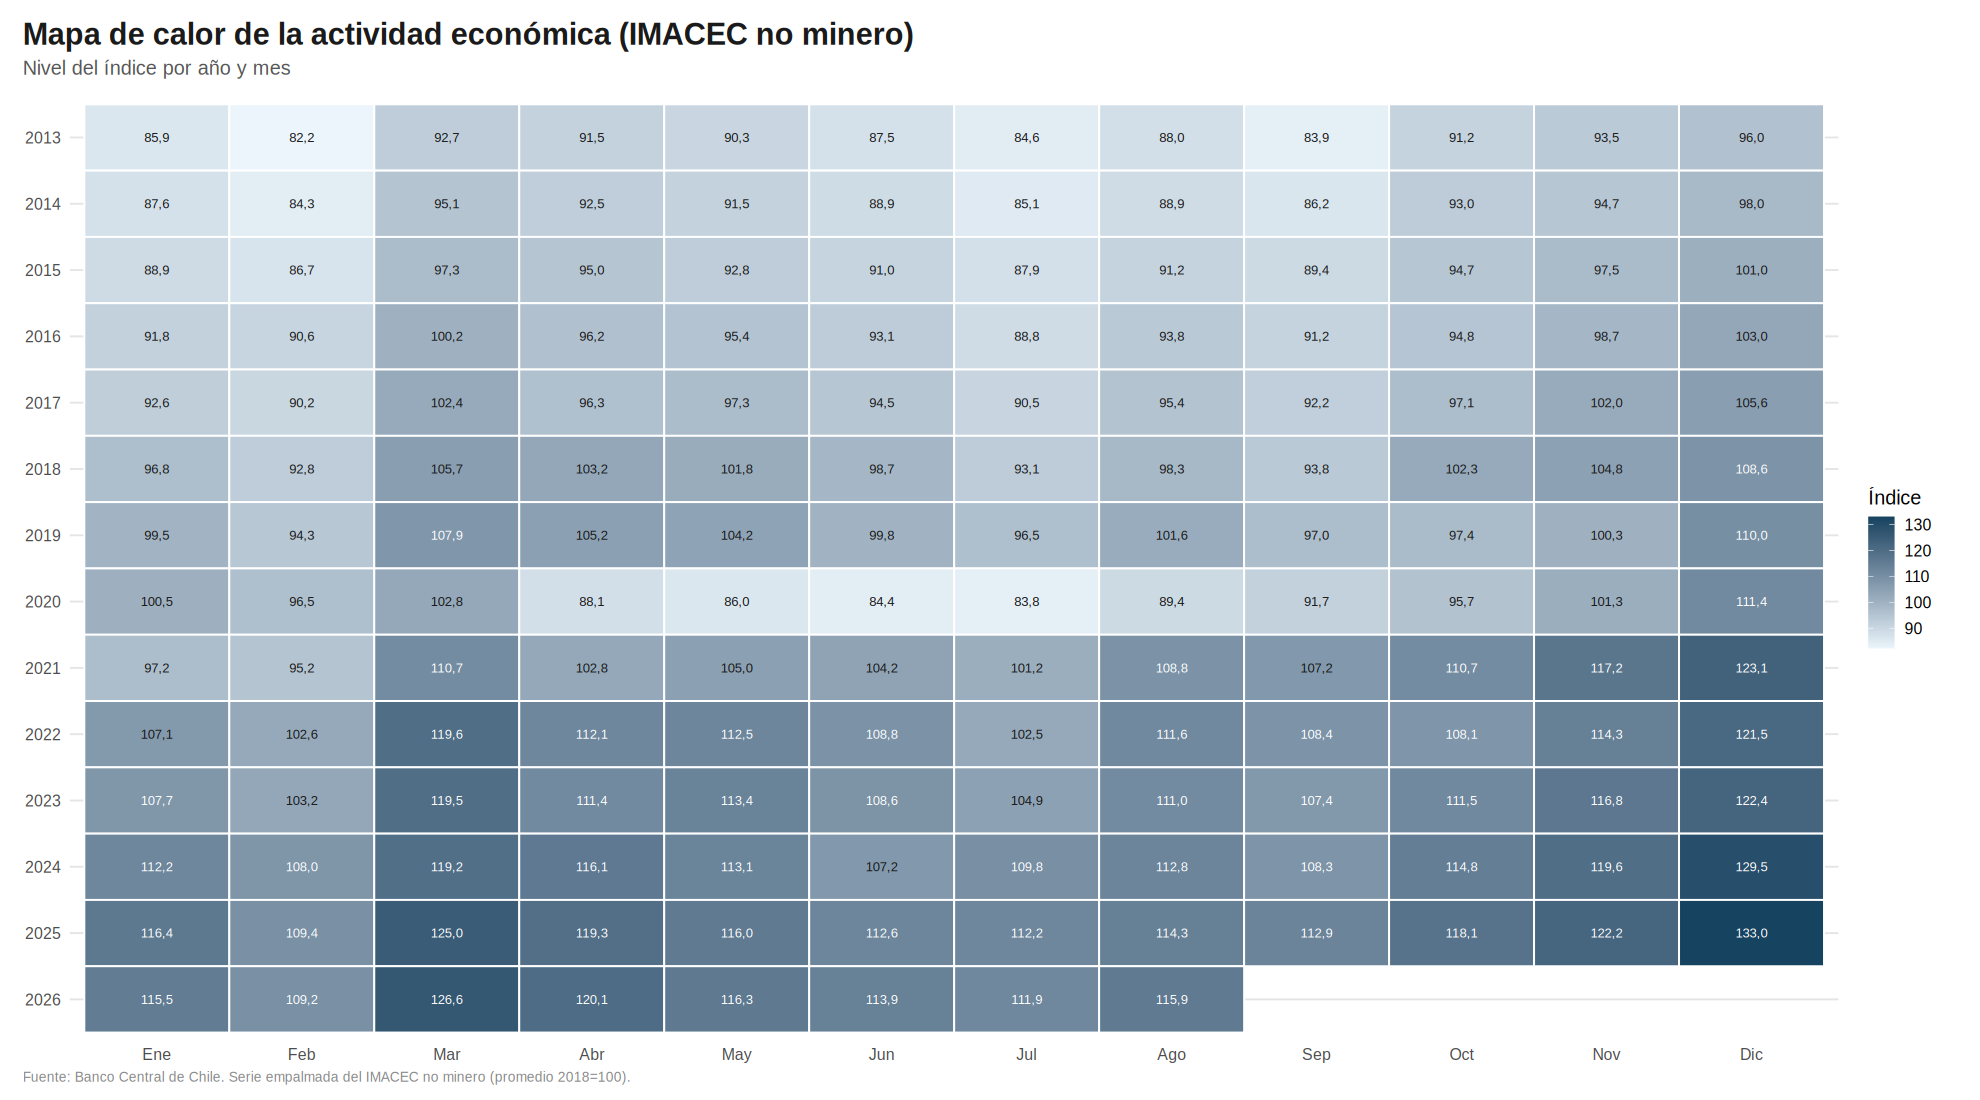


Gráficos guardados correctamente:
[1] "imacec_no_minero_mapa_calor.png" "imacec_no_minero_serie.png"     
[3] "imacec_no_minero_variacion.png" 

                INTERPRETACIÓN MACROECONÓMICA DEL IMACEC
1. Shock de Oferta y Demanda (COVID-19): Los datos reflejan una 
   caída histórica a mediados de 2020. El IMACEC no minero alcanzó una 
   contracción interanual de -17,5% en mayo de 2020, evidenciando la 
   paralización de sectores clave (comercio, servicios) por las cuarentenas.

2. Sobrecalentamiento y Efecto Base: Impulsado por el retiro de fondos 
   de pensiones y las transferencias fiscales universales, el 
   indicador exhibió un violento rebote en 2021. Se alcanzó un peak de 
   crecimiento interanual de +23,4% en junio de 2021, empujando la 
   actividad muy por encima de su capacidad de tendencia.

3. Normalización y Estancamiento Reciente: Las variaciones recientes en 
   2026 evidencian un ajuste profundo posterior al endurecimiento de 
   la política monetaria. Con cifra

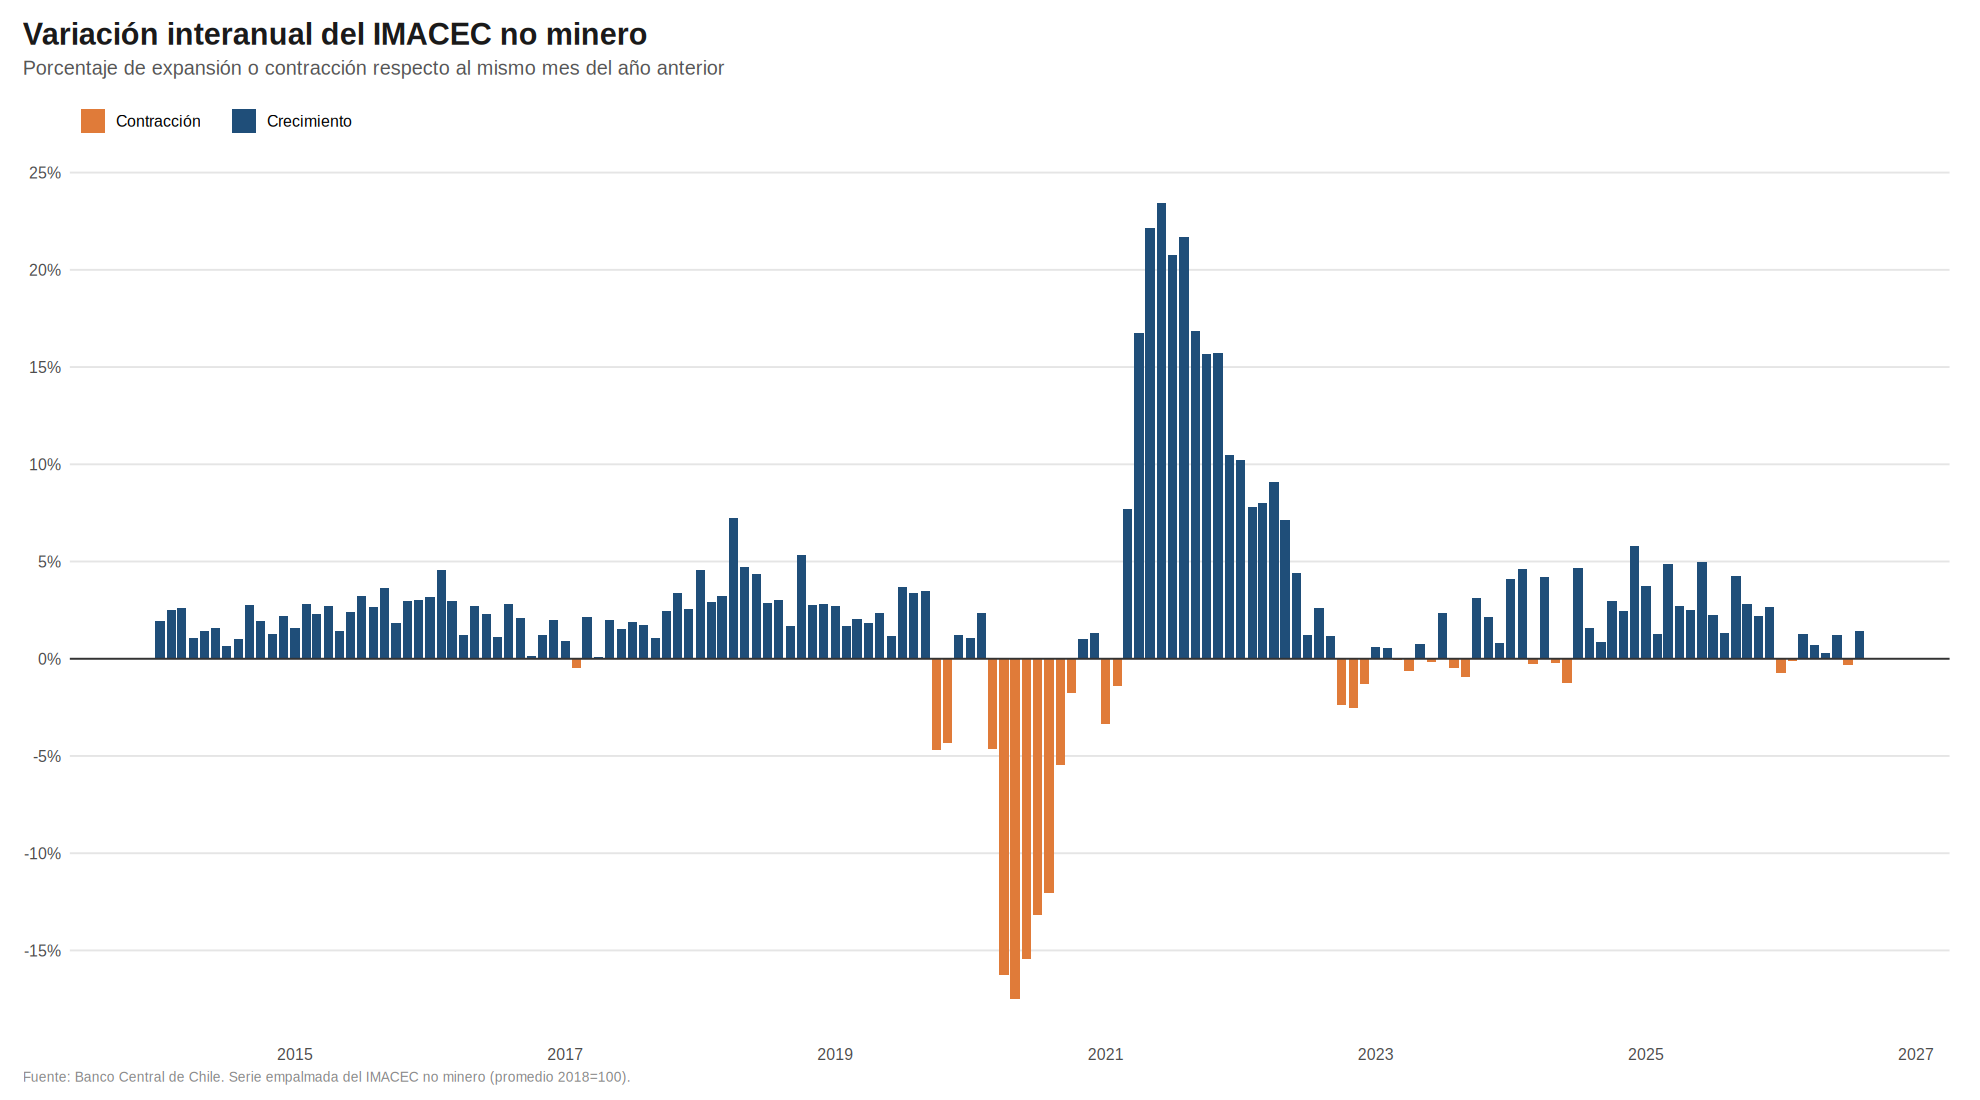

In [10]:
# ==============================================================================
# ANÁLISIS DEL IMACEC NO MINERO EN CHILE (Base 2018=100)
# ==============================================================================

# 1. Paquetes ------------------------------------------------------------------
paquetes <- c("readxl", "dplyr", "ggplot2", "scales", "tidyr", "magrittr")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

suppressPackageStartupMessages({
  library(readxl)
  library(dplyr)
  library(ggplot2)
  library(scales)
  library(tidyr)
  library(magrittr) # Carga explícita para asegurar el pipe %>%
})

# 2. Lectura y limpieza de datos -----------------------------------------------
archivo <- "CCNN2018_IMACEC_01_A (No minero)_2.xlsx"
if (!file.exists(archivo)) {
  # Ajuste por si Colab recorta el nombre al subir el archivo
  archivo <- list.files(pattern = "IMACEC.*\\.xlsx$", full.names = TRUE)[1]
  if (is.na(archivo)) stop("No encontré el archivo Excel del IMACEC.")
}
cat("Leyendo:", archivo, "\n")

raw <- read_excel(archivo, skip = 1)

meses_es <- c("ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic")

df <- raw %>%
  select(Periodo = 1, valor = 2) %>%
  filter(!is.na(Periodo), !is.na(valor)) %>%
  mutate(
    valor   = as.numeric(valor),
    mes_str = tolower(sub("\\..*", "", Periodo)),
    anio    = as.integer(sub(".*\\.", "", Periodo)),
    mes     = match(mes_str, meses_es),
    fecha   = as.Date(paste(anio, mes, "01", sep = "-"))
  ) %>%
  arrange(fecha) %>%
  mutate(
    media_12m  = as.numeric(stats::filter(valor, rep(1/12, 12), sides = 1)),
    var_12m    = (valor / lag(valor, 12) - 1) * 100,
    color_mapa = ifelse(valor > mean(valor, na.rm = TRUE) + 5, "blanco", "negro"),
    dir_var    = ifelse(var_12m > 0, "Crecimiento", "Contracción")
  ) %>%
  filter(!is.na(fecha))

cat("Observaciones procesadas:", nrow(df), "\n")

# 3. Estilo común para los gráficos --------------------------------------------
meses_es_tit <- c("Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic")
etq_fecha <- function(x) paste(meses_es_tit[as.integer(format(x, "%m"))], format(x, "%Y"))
num_es    <- function(x) number(x, accuracy = 0.1, decimal.mark = ",")

col_principal <- "#1F4E79"
col_acento    <- "#E07B39"

tema <- theme_minimal(base_size = 13) +
  theme(
    plot.title          = element_text(face = "bold", size = 20, colour = "#1A1A1A"),
    plot.subtitle       = element_text(colour = "#555555", margin = margin(b = 12)),
    plot.caption        = element_text(colour = "#888888", size = 9, hjust = 0),
    plot.title.position = "plot", plot.caption.position = "plot",
    panel.grid.minor    = element_blank(),
    panel.grid.major.x  = element_blank(),
    panel.grid.major.y  = element_line(colour = "#E5E5E5"),
    legend.position     = "top", legend.justification = "left",
    plot.background     = element_rect(fill = "white", colour = NA),
    plot.margin         = margin(15, 20, 10, 15)
  )

fuente <- "Fuente: Banco Central de Chile. Serie empalmada del IMACEC no minero (promedio 2018=100)."

options(repr.plot.width = 18, repr.plot.height = 10, repr.plot.res = 110)

# 4. Evolución de la actividad (IMACEC) ----------------------------------------
max_v <- max(df$valor, na.rm = TRUE)
min_v <- min(df$valor, na.rm = TRUE)

hitos <- bind_rows(
  df %>% filter(valor == max_v) %>% slice(1) %>% mutate(txt = paste0("Máximo: ", num_es(valor), "\n", etq_fecha(fecha))),
  df %>% filter(valor == min_v) %>% slice(1) %>% mutate(txt = paste0("Mínimo: ", num_es(valor), "\n", etq_fecha(fecha))),
  df %>% slice_tail(n = 1) %>% mutate(txt = paste0("Último: ", num_es(valor), "\n", etq_fecha(fecha)))
)

g1 <- ggplot(df, aes(x = fecha)) +
  annotate("rect", xmin = as.Date("2020-03-01"), xmax = as.Date("2021-06-01"),
           ymin = -Inf, ymax = Inf, fill = "#F3E3D8", alpha = 0.6) +
  annotate("text", x = as.Date("2020-10-15"), y = max_v * 0.95,
           label = "Pandemia\nCOVID-19", size = 3.4, colour = "#A0522D", lineheight = 0.9) +
  geom_area(aes(y = valor), fill = col_principal, alpha = 0.05) +
  geom_line(aes(y = valor, colour = "Índice mensual"), linewidth = 0.9) +
  geom_line(aes(y = media_12m, colour = "Promedio móvil 12 meses"),
            linewidth = 0.9, linetype = "22", na.rm = TRUE) +
  geom_point(data = hitos, aes(y = valor), size = 3.2, colour = col_acento,
             fill = "white", shape = 21, stroke = 1.6) +
  geom_label(data = hitos, aes(y = valor, label = txt), size = 3.2, vjust = -0.35,
             linewidth = 0, fill = alpha("white", 0.85), colour = "#333333", lineheight = 0.95) +
  scale_colour_manual(name = NULL, values = c("Índice mensual" = col_principal,
                                              "Promedio móvil 12 meses" = col_acento)) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y",
               expand = expansion(mult = c(0.01, 0.04))) +
  scale_y_continuous(labels = label_number(accuracy = 1),
                     limits = c(0, max_v + 10), expand = expansion(mult = c(0, 0.02))) +
  labs(title = "Evolución del IMACEC no minero en Chile",
       subtitle = paste0("Índice base 2018=100, ",
                         etq_fecha(min(df$fecha, na.rm = TRUE)), " - ", etq_fecha(max(df$fecha, na.rm = TRUE))),
       x = NULL, y = NULL, caption = fuente) +
  tema

print(g1)

# 5. Mapa de calor por año y mes -----------------------------------------------
g2 <- ggplot(df, aes(x = factor(mes, levels = 1:12, labels = meses_es_tit),
                     y = factor(anio, levels = rev(sort(unique(anio)))),
                     fill = valor)) +
  geom_tile(colour = "white", linewidth = 0.6) +
  geom_text(aes(label = num_es(valor), colour = color_mapa), size = 3, show.legend = FALSE) +
  scale_colour_manual(values = c("blanco" = "white", "negro" = "#1A1A1A")) +
  scale_fill_gradient(low = "#EBF5FB", high = "#154360", name = "Índice") +
  labs(title = "Mapa de calor de la actividad económica (IMACEC no minero)",
       subtitle = "Nivel del índice por año y mes", x = NULL, y = NULL, caption = fuente) +
  tema + theme(panel.grid = element_blank(), legend.position = "right")

print(g2)

# 6. Variación en 12 meses (Porcentaje) ----------------------------------------
g3 <- df %>%
  filter(!is.na(var_12m), !is.na(dir_var)) %>%
  ggplot(aes(x = fecha, y = var_12m, fill = dir_var)) +
  geom_col(width = 25) +
  geom_hline(yintercept = 0, colour = "#333333") +
  scale_fill_manual(name = NULL, values = c("Crecimiento" = col_principal, "Contracción" = col_acento)) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  scale_y_continuous(breaks = breaks_width(5), labels = label_number(accuracy = 1, suffix = "%")) +
  labs(title = "Variación interanual del IMACEC no minero",
       subtitle = "Porcentaje de expansión o contracción respecto al mismo mes del año anterior",
       x = NULL, y = NULL, caption = fuente) +
  tema

print(g3)

# 7. Guardar los gráficos en PNG -----------------------------------------------
ggsave("imacec_no_minero_serie.png",       g1, width = 12, height = 6.5, dpi = 300)
ggsave("imacec_no_minero_mapa_calor.png",  g2, width = 11, height = 8,   dpi = 300)
ggsave("imacec_no_minero_variacion.png",   g3, width = 12, height = 5.5, dpi = 300)
cat("\nGráficos guardados correctamente:\n")
print(list.files(pattern = "^imacec.*\\.png$"))

# 8. Interpretación Macroeconómica ---------------------------------------------
cat("\n=======================================================================\n")
cat("                INTERPRETACIÓN MACROECONÓMICA DEL IMACEC\n")
cat("=======================================================================\n")
cat("1. Shock de Oferta y Demanda (COVID-19): Los datos reflejan una \n")
cat("   caída histórica a mediados de 2020. El IMACEC no minero alcanzó una \n")
cat("   contracción interanual de -17,5% en mayo de 2020, evidenciando la \n")
cat("   paralización de sectores clave (comercio, servicios) por las cuarentenas.\n\n")

cat("2. Sobrecalentamiento y Efecto Base: Impulsado por el retiro de fondos \n")
cat("   de pensiones y las transferencias fiscales universales, el \n")
cat("   indicador exhibió un violento rebote en 2021. Se alcanzó un peak de \n")
cat("   crecimiento interanual de +23,4% en junio de 2021, empujando la \n")
cat("   actividad muy por encima de su capacidad de tendencia.\n\n")

cat("3. Normalización y Estancamiento Reciente: Las variaciones recientes en \n")
cat("   2026 evidencian un ajuste profundo posterior al endurecimiento de \n")
cat("   la política monetaria. Con cifras que fluctúan marginalmente entre \n")
cat("   contracciones leves y expansiones moderadas (+1,4% en agosto 2026), \n")
cat("   la actividad económica refleja un ciclo de bajo dinamismo.\n")
cat("=======================================================================\n")